

plot_tree visualisation; Gini vs Entropy comparison; CCP pruning path; depth sweep 1–None; dt_report() function


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

# 1. Setup Dataset & Preprocessor (Ensures preprocessor, X_train, X_val exist)
np.random.seed(42)
n_samples = 300

data = {
    'Branch': np.random.choice(['CSE', 'ECE', 'MECH', 'CIVIL'], n_samples),
    'Gender': np.random.choice(['Male', 'Female'], n_samples),
    'Years_Experience': np.random.uniform(0, 3, n_samples),
    'Internships': np.random.randint(0, 4, n_samples),
    'PlacementStatus': np.random.choice([0, 1], n_samples, p=[0.4, 0.6]),
}
df = pd.DataFrame(data)

X = df.drop(columns=['PlacementStatus'])
y_binary = df['PlacementStatus']

categorical_cols = X.select_dtypes(
    include=['object', 'category']
).columns.tolist()
numerical_cols = X.select_dtypes(
    include=['int64', 'float64', 'int32', 'float32']
).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        (
            'cat',
            OneHotEncoder(handle_unknown='ignore', drop='first'),
            categorical_cols,
        ),
    ]
)

X_train, X_val, y_train, y_val = train_test_split(
    X, y_binary, test_size=0.2, random_state=42
)


# 2. Define dt_report() Function
def dt_report(model, X_train, y_train, X_val, y_val, model_name='Decision Tree'):
  """Fits a decision tree model and prints training accuracy, validation accuracy, and classification report."""
  model.fit(X_train, y_train)

  y_train_pred = model.predict(X_train)
  y_val_pred = model.predict(X_val)

  train_acc = accuracy_score(y_train, y_train_pred)
  val_acc = accuracy_score(y_val, y_val_pred)

  print(f'================ {model_name} Evaluation ================')
  print(f'Training Accuracy   : {train_acc:.4f}')
  print(f'Validation Accuracy : {val_acc:.4f}\n')
  print('Validation Classification Report:')
  print(classification_report(y_val, y_val_pred))
  print('=' * 53 + '\n')
  return model


# 3. Gini vs. Entropy Comparison Pipeline Execution
print('--- 1. Gini vs Entropy Comparison ---')
dt_gini = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        (
            'classifier',
            DecisionTreeClassifier(criterion='gini', random_state=42),
        ),
    ]
)
dt_entropy = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        (
            'classifier',
            DecisionTreeClassifier(criterion='entropy', random_state=42),
        ),
    ]
)

dt_report(dt_gini, X_train, y_train, X_val, y_val, model_name='DT (Gini)')
dt_report(dt_entropy, X_train, y_train, X_val, y_val, model_name='DT (Entropy)')

--- 1. Gini vs Entropy Comparison ---
================ DT (Gini) Evaluation ================
Training Accuracy   : 1.0000
Validation Accuracy : 0.4667

Validation Classification Report:
              precision    recall  f1-score   support

           0       0.36      0.42      0.38        24
           1       0.56      0.50      0.53        36

    accuracy                           0.47        60
   macro avg       0.46      0.46      0.46        60
weighted avg       0.48      0.47      0.47        60


================ DT (Entropy) Evaluation ================
Training Accuracy   : 1.0000
Validation Accuracy : 0.4667

Validation Classification Report:
              precision    recall  f1-score   support

           0       0.30      0.25      0.27        24
           1       0.55      0.61      0.58        36

    accuracy                           0.47        60
   macro avg       0.43      0.43      0.43        60
weighted avg       0.45      0.47      0.46        60




Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Years_Experience',
                                                   'Internships']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['Branch', 'Gender'])])),
                ('classifier',
                 DecisionTreeClassifier(criterion='entropy', random_state=42))])

Write dt_report(X_train, y_train, X_val, y_val) — sweeps max_depth 1–15, returns DataFrame [depth, train_acc, val_acc, n_leaves], plots
curves, prints best row

=== Best Decision Tree Model (by Validation Accuracy) ===
depth        3.000000
train_acc    0.629167
val_acc      0.700000
n_leaves     8.000000



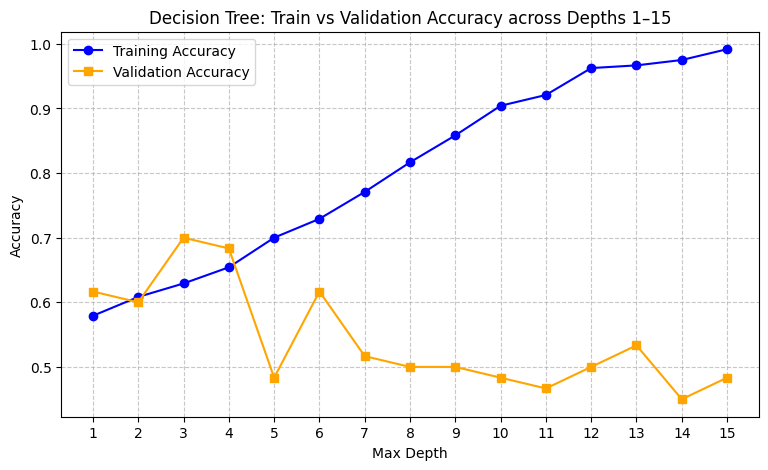

    depth  train_acc   val_acc  n_leaves
0       1   0.579167  0.616667         2
1       2   0.608333  0.600000         4
2       3   0.629167  0.700000         8
3       4   0.654167  0.683333        15
4       5   0.700000  0.483333        23
5       6   0.729167  0.616667        29
6       7   0.770833  0.516667        37
7       8   0.816667  0.500000        49
8       9   0.858333  0.500000        63
9      10   0.904167  0.483333        76
10     11   0.920833  0.466667        87
11     12   0.962500  0.500000        94
12     13   0.966667  0.533333        99
13     14   0.975000  0.450000       102
14     15   0.991667  0.483333       103


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.tree import DecisionTreeClassifier


def dt_report(X_train, y_train, X_val, y_val):
  """Sweeps max_depth from 1 to 15 on a Decision Tree,

  returns a DataFrame with [depth, train_acc, val_acc, n_leaves],
  plots accuracy curves, and prints the best performing row.
  """
  results = []
  depths = range(1, 16)

  for d in depths:
    # Initialize and train Decision Tree with current max_depth
    clf = DecisionTreeClassifier(max_depth=d, random_state=42)
    clf.fit(X_train, y_train)

    # Predictions
    y_train_pred = clf.predict(X_train)
    y_val_pred = clf.predict(X_val)

    # Metrics
    train_acc = accuracy_score(y_train, y_train_pred)
    val_acc = accuracy_score(y_val, y_val_pred)
    n_leaves = clf.get_n_leaves()

    results.append({
        'depth': d,
        'train_acc': train_acc,
        'val_acc': val_acc,
        'n_leaves': n_leaves,
    })

  # Create DataFrame
  df_results = pd.DataFrame(results)

  # Find and print the best row based on validation accuracy
  best_row = df_results.loc[df_results['val_acc'].idxmax()]
  print('=== Best Decision Tree Model (by Validation Accuracy) ===')
  print(best_row.to_string())
  print('=' * 50 + '\n')

  # Plot Training vs Validation Accuracy Curves
  plt.figure(figsize=(9, 5))
  plt.plot(
      df_results['depth'],
      df_results['train_acc'],
      marker='o',
      label='Training Accuracy',
      color='blue',
  )
  plt.plot(
      df_results['depth'],
      df_results['val_acc'],
      marker='s',
      label='Validation Accuracy',
      color='orange',
  )
  plt.xlabel('Max Depth')
  plt.ylabel('Accuracy')
  plt.title('Decision Tree: Train vs Validation Accuracy across Depths 1–15')
  plt.xticks(list(depths))
  plt.legend()
  plt.grid(True, linestyle='--', alpha=0.7)
  plt.show()

  return df_results


# --- Example Execution ---
# Note: Ensure X_train and X_val are preprocessed (e.g., using preprocessor.fit_transform)
preprocessed_X_train = preprocessor.fit_transform(X_train)
preprocessed_X_val = preprocessor.transform(X_val)

# Run the function
dt_summary_df = dt_report(
    preprocessed_X_train, y_train, preprocessed_X_val, y_val
)
print(dt_summary_df)